# Quantum computing patents: a landscape

**Data:** harmonized applicant–family table (`harmonization_output.csv`), one row per applicant per patent family.
**Unit of count:** the DOCDB patent family: one invention counts once, however many offices it was filed in.


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats

DATA_PATH = "harmonization_output.csv"

SECTOR = "COMPANY"     # market analysis is limited to firms
YEAR_MAX = 2023        # last filing year included (see section 4)
SPLIT_YEAR = 2015      # incumbent = firm with >= MIN_FAMILIES families before this year
MIN_FAMILIES = 1

# Periods used to follow concentration over time
PERIOD_BINS = [-np.inf, 2014, 2018, YEAR_MAX]
PERIOD_LABELS = ["up to 2014", "2015-2018", f"2019-{YEAR_MAX}"]

df = pd.read_csv(DATA_PATH)
print(f"{len(df):,} rows | {df['docdb_family_id'].nunique():,} families | "
      f"years {df['family_year'].min()}-{df['family_year'].max()}")

20,895 rows | 12,596 families | years 1991-2023


## 1. Patenting trend

How many new patent families are filed each year, all applicants together. This sets the scale for everything that follows.

family_year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
families,60,75,87,72,59,75,71,75,107,135,190,275,438,736,1109,1419,1896,2486,2874


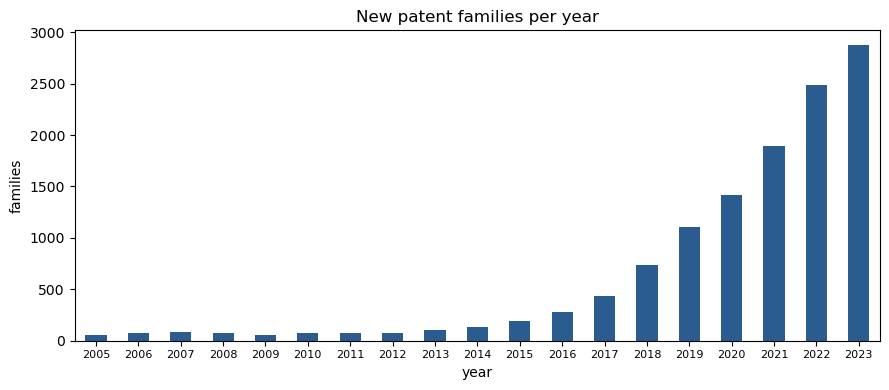

In [30]:
def families_per_year(df, year_from=2005):
    "Number of distinct patent families per filing year."
    return df.drop_duplicates("docdb_family_id").groupby("family_year").size().loc[year_from:YEAR_MAX]


def plot_families_per_year(counts):
    ax = counts.plot.bar(figsize=(9, 4), rot=0, color="#2b5c8f", title="New patent families per year")
    ax.set(xlabel="year", ylabel="families")
    ax.tick_params(axis="x", labelsize=8)
    plt.tight_layout()
    plt.show()


trend = families_per_year(df)
display(trend.to_frame("families").T)
plot_families_per_year(trend)

**Results.** Filing is very recent: about 75 families a year around 2010, about 2,900 in 2023. More than three quarters of all families (about 9,800 of 12,600) were filed in 2019–2023, and growth speeds up after 2017.
For this reason, we decided to include 2023 in the analysis, while remaining mindful of the limitations posed by some missing data in PATSTAT.



## 2. Who patents?

We count the applicants by type (individual, company, university, public body), then look at which combinations of types file together.

### Individuals
Individuals are counted here and then **excluded from all later analysis**: they are not market actors, and their names are not harmonized.
The count uses `psn_id`, and one person can have several IDs, so the number is **indicative**, an upper bound.

In [31]:
def count_individuals(df):
    "Unique individual IDs and families filed by individuals only."
    is_individual = df["psn_sector_imputed"].eq("INDIVIDUAL")
    only_individuals = is_individual.groupby(df["docdb_family_id"]).all()
    return pd.Series({
        "unique individual IDs (indicative)": df.loc[is_individual, "psn_id"].nunique(),
        "families filed by individuals only": only_individuals.sum(),
        "share of all families (%)": round(only_individuals.mean() * 100, 1),
    }).to_frame("value")


count_individuals(df)

,value
unique individual IDs (indicative),2287.0
families filed by individuals only,415.0
share of all families (%),3.3


### Organisations
Each harmonized entity gets **one sector**, the most frequent one across its rows. Without this, an entity coded partly as company and partly as government (e.g. RIKEN) would be split between groups.

The bar chart counts families by the **mix of applicant types**, so it also shows how often companies co-file with universities or public bodies.

,unique entities
COMPANY,1326
UNIVERSITY,624
GOV NON-PROFIT,190
TOTAL,2140


,families,share (%)
COMPANY,7944,63.1
UNIVERSITY,2337,18.6
GOV NON-PROFIT,559,4.4
COMPANY + INDIVIDUAL,547,4.3
INDIVIDUAL,415,3.3
COMPANY + UNIVERSITY,303,2.4
GOV NON-PROFIT + UNIVERSITY,136,1.1
INDIVIDUAL + UNIVERSITY,132,1.0
Other combinations,223,1.8
TOTAL FAMILIES,12596,100.0


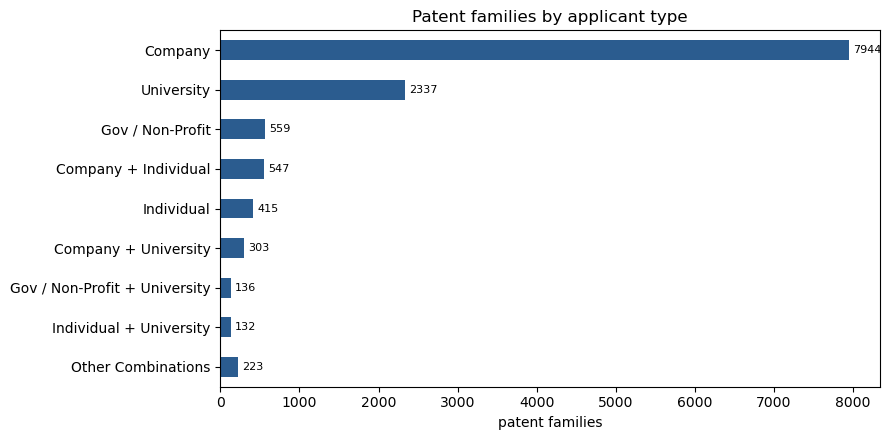

In [32]:
def assign_entity_sector(df):
    "Add `entity_sector`: the most frequent sector of each harmonized entity."
    named = df.dropna(subset=["harmonized_name_final"])
    sector = named.groupby("harmonized_name_final")["psn_sector_imputed"].agg(lambda s: s.mode().iat[0])
    return df.assign(entity_sector=df["harmonized_name_final"].map(sector))


def count_entities_by_type(df):
    "Unique harmonized entities per sector."
    entities = df.dropna(subset=["entity_sector"]).drop_duplicates("harmonized_name_final")
    counts = entities["entity_sector"].value_counts()
    return pd.concat([counts, pd.Series({"TOTAL": counts.sum()})]).to_frame("unique entities")


def families_by_applicant_mix(df, top_n=8):
    "Families per combination of applicant types; rare combinations are grouped."
    mix = (df.groupby("docdb_family_id")["psn_sector_imputed"]
             .agg(lambda s: " + ".join(sorted(s.dropna().unique())))
             .value_counts())
    rest = pd.Series({"Other combinations": mix.iloc[top_n:].sum()})
    return pd.concat([mix.head(top_n), rest]) if len(mix) > top_n else mix


def plot_applicant_mix(mix):
    labels = mix.index.str.title().str.replace("Gov Non-Profit", "Gov / Non-Profit")
    ax = pd.Series(mix.values, index=labels).iloc[::-1].plot.barh(color="#2b5c8f", figsize=(9, 4.5))
    ax.bar_label(ax.containers[0], padding=3, fontsize=8)
    ax.set(title="Patent families by applicant type", xlabel="patent families", ylabel="")
    plt.tight_layout()
    plt.show()

def mix_table(mix):
    "Families per applicant mix, with share of all families and a total row."
    table = mix.to_frame("families")
    table["share (%)"] = (table["families"] / table["families"].sum() * 100).round(1)
    table.loc["TOTAL FAMILIES"] = [table["families"].sum(), 100.0]
    return table.astype({"families": int})


df = assign_entity_sector(df)
display(count_entities_by_type(df))

mix = families_by_applicant_mix(df)
display(mix_table(mix))
plot_applicant_mix(mix)

**Results.** Companies dominate: 63% of families are filed by companies alone, universities alone file 19%, public bodies 4%. Joint filing between companies and universities is rare (2.4% of families), so firm–university collaboration, where it exists, rarely shows up as co-ownership. Individuals file only 3% of families on their own.


## 3. Geography

All organisations (companies, universities, public bodies); individuals excluded. Period: 2010 to `YEAR_MAX`.

- **Country of a family:** the applicant's country; if missing, the office of first filing (CN → China, EP → Europe). Without this fallback China would almost disappear, because the country field is missing mostly for Chinese filings.
- **Regions:** China, US, Europe (EU + UK, CH, NO, IS), rest of world. A family with applicants from several regions counts in each.


In [33]:
EUROPE = {"AT","BE","BG","CY","CZ","DE","DK","EE","ES","FI","FR","GR","HR","HU","IE","IT","LT","LU",
          "LV","MT","NL","PL","PT","RO","SE","SI","SK","GB","CH","NO","IS","EP"}  # EP = European Patent Office
REGIONS = ["China", "US", "Europe", "Rest of world"]
SECTORS = ["COMPANY", "UNIVERSITY", "GOV NON-PROFIT"]
GEO_FROM = 2010


def to_region(code):
    if code in ("CN", "US"):
        return {"CN": "China", "US": "US"}[code]
    return "Europe" if code in EUROPE else "Rest of world"


def build_geo_links(df):
    "One row per (family, region, sector) for organisations; a multi-country family counts in each region."
    orgs = df[df["entity_sector"].isin(SECTORS) & df["family_year"].between(GEO_FROM, YEAR_MAX)]
    from_office = orgs["applicant_ctry"].isna()
    orgs = orgs.assign(region=orgs["applicant_ctry"].fillna(orgs["first_office"]).map(to_region))
    print(f"country taken from office of first filing for {from_office.mean():.0%} of rows")
    return (orgs[["docdb_family_id", "family_year", "region", "entity_sector", "offices"]]
            .drop_duplicates(["docdb_family_id", "region", "entity_sector"])
            .set_axis(["family", "year", "region", "sector", "offices"], axis=1))


geo = build_geo_links(df)
geo.groupby("region")["family"].nunique().reindex(REGIONS).to_frame("families")

country taken from office of first filing for 42% of rows


,families
region,
China,4764
US,3695
Europe,1794
Rest of world,2155


region,China,US,Europe,Rest of world
year,,,,
2010,17,17,11,22
2011,5,18,7,38
2012,15,23,4,23
2013,23,39,7,42
2014,40,47,21,30
2015,44,88,40,42
2016,59,131,40,79
2017,108,224,89,82
2018,212,355,122,113


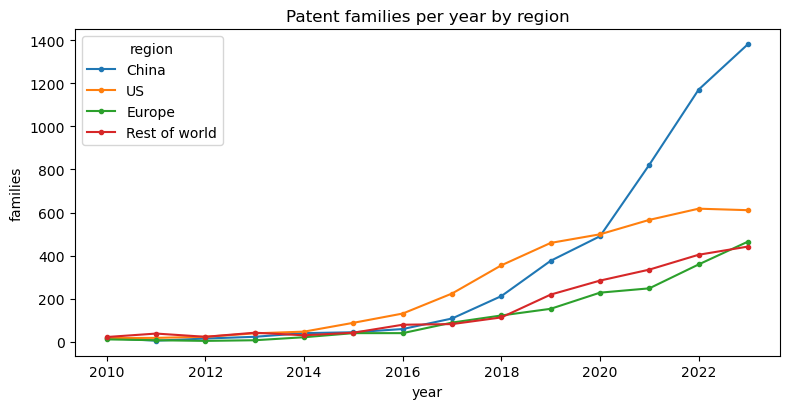

In [34]:
def families_by_region(geo):
    return geo.drop_duplicates(["family", "region"]).pivot_table(
        index="year", columns="region", values="family", aggfunc="count", fill_value=0)[REGIONS]


def plot_families_by_region(table):
    ax = table.plot(marker="o", ms=3, figsize=(8, 4.2), title="Patent families per year by region")
    ax.set(xlabel="year", ylabel="families")
    plt.tight_layout()
    plt.show()


region_table = families_by_region(geo)
display(region_table)
plot_families_by_region(region_table)

China                                US                            \
sector COMPANY UNIVERSITY GOV NON-PROFIT COMPANY UNIVERSITY GOV NON-PROFIT   
year                                                                         
2010       6.0       94.0            0.0    65.0       35.0            0.0   
2011      20.0       80.0            0.0    67.0       28.0            6.0   
2012      20.0       80.0            0.0    83.0        9.0            9.0   
2013      30.0       70.0            0.0    77.0       13.0           10.0   
2014      17.0       80.0            2.0    79.0       15.0            6.0   
2015      36.0       64.0            0.0    77.0       20.0            3.0   
2016      39.0       59.0            2.0    83.0       13.0            4.0   
2017      43.0       56.0            1.0    86.0       13.0            2.0   
2018      45.0       52.0            3.0    84.0       14.0            2.0   
2019      58.0       40.0            2.0    85.0       13.0            2.0   
2020      63.0       33.0            4.0    81.0       17.0            2.0   
2021      64.0       32.0            4.0    83.0       15.0            3.0   
2022      68.0       26.0            6.0    83.0       15.0            2.0   
2023      68.0       25.0            7.0    85.0       14.0            1.0   

        Europe                            
sector COMPANY UNIVERSITY GOV NON-PROFIT  
year                                      
2010      45.0       36.0           18.0  
2011      56.0       11.0           33.0  
2012      75.0       25.0            0.0  
2013      56.0       22.0           22.0  
2014      60.0       32.0            8.0  
2015      73.0       16.0           11.0  
2016      60.0       33.0            7.0  
2017      79.0       12.0            9.0  
2018      87.0        6.0            6.0  
2019      78.0       14.0            8.0  
2020      74.0       13.0           14.0  
2021      62.0       20.0           18.0  
2022      79.0       12.0            9.0  
2023      71.0       14.0           16.0

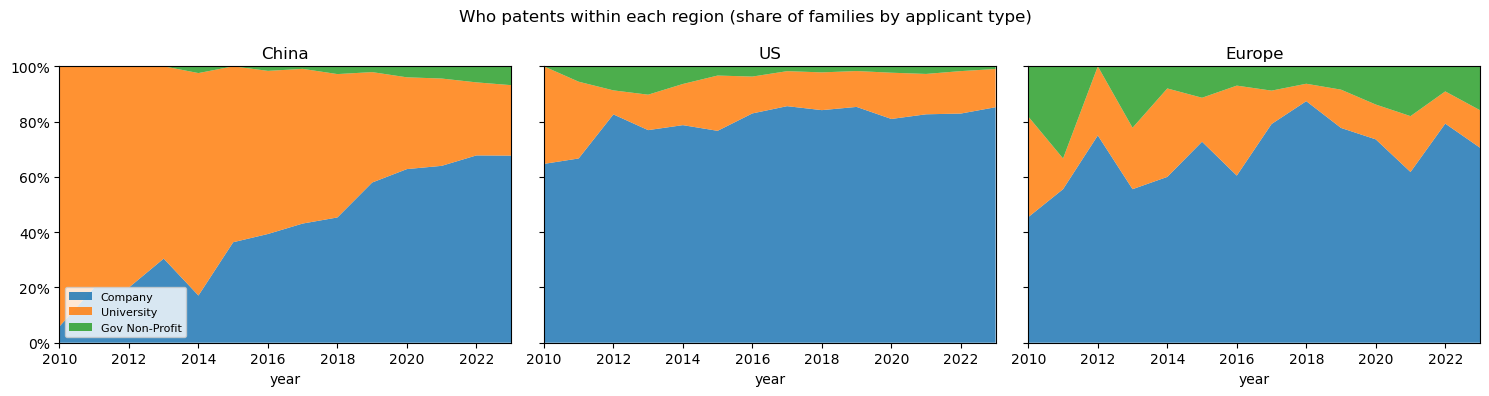

In [35]:
def sector_mix(geo, region):
    "Yearly share of each applicant type in a region (a co-owned family counts for each type)."
    counts = (geo[geo["region"] == region]
              .pivot_table(index="year", columns="sector", values="family", aggfunc="count", fill_value=0)
              .reindex(columns=SECTORS, fill_value=0))
    return counts.div(counts.sum(axis=1), axis=0) * 100


def plot_sector_mix(geo, regions=("China", "US", "Europe")):
    fig, axes = plt.subplots(1, len(regions), figsize=(15, 4), sharey=True)
    for ax, region in zip(axes, regions):
        mix = sector_mix(geo, region)
        ax.stackplot(mix.index, mix.T.values, labels=[s.title() for s in mix.columns], alpha=0.85)
        ax.set(title=region, xlabel="year", xlim=(GEO_FROM, YEAR_MAX), ylim=(0, 100))
        ax.yaxis.set_major_formatter(PercentFormatter(100))
    axes[0].legend(loc="lower left", fontsize=8)
    fig.suptitle("Who patents within each region (share of families by applicant type)")
    plt.tight_layout()
    plt.show()


display(pd.concat({r: sector_mix(geo, r).round(0) for r in ["China", "US", "Europe"]}, axis=1))
plot_sector_mix(geo)

**Results.**
- **Volume.** Over 2010–2023 China has the most families (about 4,800), ahead of the US (3,700), Europe (1,800) and the rest of the world (2,200). The US led until 2020; China overtook it in 2021 and in 2023 files more than twice as many families (about 1,380 vs 610). US filing has been flat at about 600 a year since 2021, while Europe grows steadily (from 40 in 2015 to 465 in 2023) but stays far behind.
- **Who patents.** The three regions are organised differently. In China patenting has moved from universities to companies: companies held 6% of Chinese families in 2010 and 68% in 2023. In the US companies have held more than 80% throughout. Europe has the largest share of public research bodies (often 10–18% of families).


## 4. Scope of the market analysis

From here on: **companies only**, **families filed up to `YEAR_MAX` = 2023**.

- *Companies only:* concentration and consolidation describe competition between firms. Universities and public bodies follow other incentives.
- *2023 included:* applications are published about 18 months after filing. With a recent PATSTAT edition, 2023 is almost complete; it also has more families than 2022, so there is no visible truncation drop. Including it keeps about 220 firms whose first family is from 2023.

Every later cell uses the same table: one row per (firm, family).

In [36]:
def build_firm_links(df, sector):
    "One row per (firm, family) for the chosen sector, all years."
    return (df[df["entity_sector"].eq(sector)]
            [["harmonized_name_final", "docdb_family_id", "family_year"]]
            .drop_duplicates(["harmonized_name_final", "docdb_family_id"])
            .set_axis(["firm", "family", "year"], axis=1))


links_all = build_firm_links(df, SECTOR)
firms = links_all[links_all["year"] <= YEAR_MAX]
print(f"{firms['firm'].nunique():,} firms | {firms['family'].nunique():,} families | "
      f"{firms['year'].min()}-{YEAR_MAX}")

1,326 firms | 8,961 families | 1991-2023


## 5. Concentration

How evenly are patents spread across firms? Each firm's size is its number of distinct families. Co-owned families count once for each owner, so *families (sum)* is larger than the number of unique families.

| measure | reads as |
|---|---|
| CR4 / CR8 | share of families held by the 4 / 8 largest firms |
| HHI | sum of squared shares (0 = dispersed, 1 = monopoly); **1/HHI** = number of equal-sized firms giving the same HHI |
| CV | spread of firm sizes relative to the mean |
| Gini | inequality of sizes (0 = all equal, 1 = one firm holds everything) |
| Lotka slope | slope of log(firms with *n* families) on log(*n*); steeper = more one-off filers. Descriptive only |

,firms,families (sum),CR4 (%),CR8 (%),HHI,1/HHI,CV,Gini,Lotka slope
"Companies, up to 2023",1326,9844,23.893,32.497,0.023,44.024,5.398,0.79,-0.917


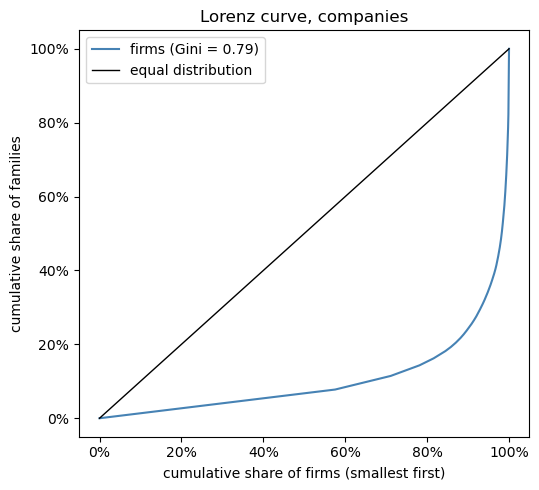

In [37]:
def families_per_firm(links):
    return links.groupby("firm")["family"].nunique().to_numpy()


def gini(sizes):
    sizes = np.sort(sizes)
    n = len(sizes)
    return (2 * np.arange(1, n + 1) - n - 1) @ sizes / (n * sizes.sum())


def lotka_slope(sizes):
    freq = pd.Series(sizes).value_counts()  # n families -> number of firms
    if len(freq) < 3:
        return np.nan
    return stats.linregress(np.log(freq.index), np.log(freq.values)).slope


def concentration_measures(sizes):
    shares = np.sort(sizes)[::-1] / sizes.sum()
    hhi = (shares ** 2).sum()
    return {
        "firms": len(sizes),
        "families (sum)": int(sizes.sum()),
        "CR4 (%)": shares[:4].sum() * 100,
        "CR8 (%)": shares[:8].sum() * 100,
        "HHI": hhi,
        "1/HHI": 1 / hhi,
        "CV": sizes.std(ddof=1) / sizes.mean(),
        "Gini": gini(sizes),
        "Lotka slope": lotka_slope(sizes),
    }


def plot_lorenz(sizes):
    sizes = np.sort(sizes)
    cum_firms = np.arange(len(sizes) + 1) / len(sizes)
    cum_families = np.r_[0, sizes.cumsum() / sizes.sum()]
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.plot(cum_firms, cum_families, color="steelblue", label=f"firms (Gini = {gini(sizes):.2f})")
    ax.plot([0, 1], [0, 1], color="black", lw=1, label="equal distribution")
    ax.set(title="Lorenz curve, companies", xlabel="cumulative share of firms (smallest first)",
           ylabel="cumulative share of families")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend()
    plt.tight_layout()
    plt.show()


sizes = families_per_firm(firms)
display(pd.DataFrame([concentration_measures(sizes)], index=[f"Companies, up to {YEAR_MAX}"]).round(3))
plot_lorenz(sizes)

**Results.** The 4 largest firms hold 24% of company families and the 8 largest 33%. 1/HHI ≈ 44: the market behaves as if 43 equal-sized firms competed. Gini ≈ 0.79: a few large filers and a long tail of firms with one or two families. The field is unequal, but it is not an oligopoly.



## 6. Consolidation

A single concentration figure cannot show **direction**. Here the same measures are computed per period:
if CR4 and HHI rise, the field is consolidating around a few firms; if they fall, new firms are taking share.
1/HHI moves the other way: if it rises, the market behaves as if more equal-sized firms competed.

,CR4 (%),CR8 (%),HHI,1/HHI
up to 2014,35.842,51.531,0.049,20.429
2015-2018,34.925,46.901,0.043,23.239
2019-2023,26.036,33.855,0.026,38.327


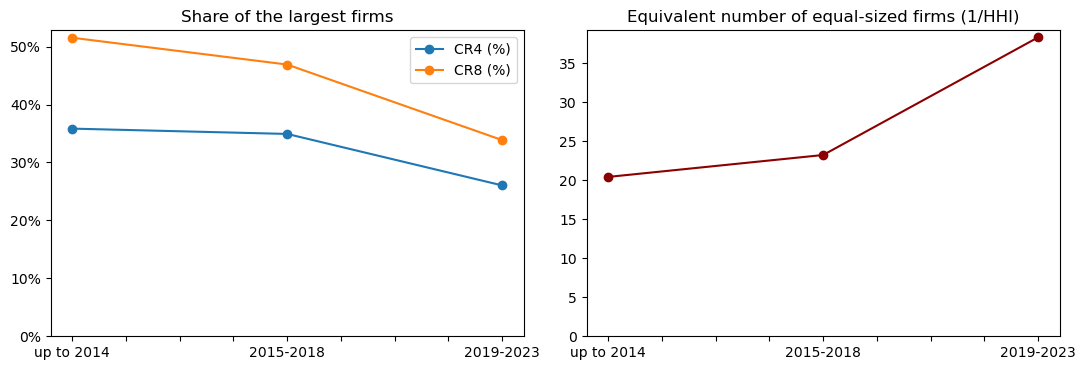

In [38]:
def concentration_by_period(links):
    period = pd.cut(links["year"], bins=PERIOD_BINS, labels=PERIOD_LABELS)
    rows = {p: concentration_measures(families_per_firm(g)) for p, g in links.groupby(period, observed=True)}
    return pd.DataFrame(rows).T[["CR4 (%)", "CR8 (%)", "HHI", "1/HHI"]]


def plot_concentration_trend(table):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    table[["CR4 (%)", "CR8 (%)"]].plot(ax=axes[0], marker="o", title="Share of the largest firms")
    table["1/HHI"].plot(ax=axes[1], marker="o", color="darkred",
                        title="Equivalent number of equal-sized firms (1/HHI)")
    axes[0].yaxis.set_major_formatter(PercentFormatter(100))
    for ax in axes:
        ax.set(xlabel="", ylim=(0, None))
    plt.tight_layout()
    plt.show()


by_period = concentration_by_period(firms)
display(by_period.round(3))
plot_concentration_trend(by_period)

**Results.** Concentration falls: CR4 drops from 36% (up to 2014) to 26% (2019–2023), and 1/HHI rises from about 20 to 38. New firms are taking share faster than the leaders grow, so the field is **widening, not consolidating**.


### Largest firms
**Incumbent** = at least one family before `SPLIT_YEAR` (2015); everyone else is an **entrant**.
*Share* is computed over all unique company families up to `YEAR_MAX`.

In [39]:
def top_firms(links, n=20):
    "Largest firms with first filing year and incumbent/entrant status."
    early = links[links["year"] < SPLIT_YEAR].groupby("firm")["family"].nunique()
    by_firm = links.groupby("firm")
    table = pd.DataFrame({"families": by_firm["family"].nunique(), "first year": by_firm["year"].min()})
    table["share (%)"] = table["families"] / links["family"].nunique() * 100
    table["status"] = np.where(table.index.isin(early[early >= MIN_FAMILIES].index), "incumbent", "entrant")
    return table.nlargest(n, "families").round(1)


top_firms(firms)

,families,first year,share (%),status
firm,,,,
ORIGIN QUANTUM COMPUTING TECH HEFEI,972,2017,10.8,entrant
IBM,772,1994,8.6,incumbent
BEIJING BAIDU NETCOM SCIENCE TECH,354,2019,4.0,entrant
MICROSOFT TECH LICENSING,254,2004,2.8,incumbent
GOOGLE,243,2013,2.7,incumbent
FUJITSU,229,1993,2.6,incumbent
D WAVE SYSTEMS,202,1999,2.3,incumbent
IONQ,173,2017,1.9,entrant
INTEL,166,2000,1.9,incumbent


**Results.** The top 20 mixes 12 incumbents (IBM, Microsoft, Google, Fujitsu, D-Wave, Japanese electronics groups) and 8 entrants. Origin Quantum, founded in 2017, is now the largest filer, ahead of IBM.

### IBM vs Origin Quantum: two filing strategies
Origin ranks first by number of families, IBM second. We compare their families filed in 2017–2021: both firms are active, and these families have had time to be filed abroad (about 30 months after the first filing).

,families,filed_in_2plus_offices_pct
harmonized_name_final,,
IBM,495,58.0
ORIGIN QUANTUM COMPUTING TECH HEFEI,379,14.0


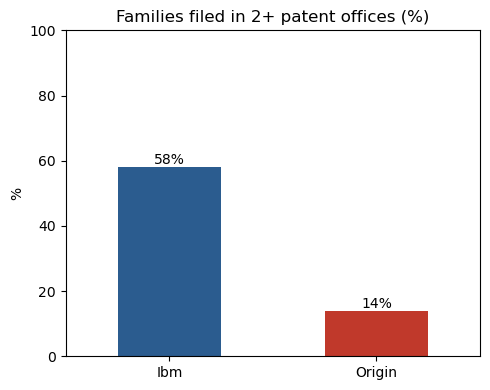

In [40]:
COMPARE = ["IBM", "ORIGIN QUANTUM COMPUTING TECH HEFEI"]
COMPARE_FROM, COMPARE_TO = 2017, 2021  # same age; 2021 = last year with complete foreign filings

def international_share(df, names):
    "Families since COMPARE_FROM and share filed in 2+ patent offices, per firm."
    fam = df[df["family_year"].between(COMPARE_FROM, COMPARE_TO)]
    fam = fam[fam["harmonized_name_final"].isin(names)].drop_duplicates(["harmonized_name_final", "docdb_family_id"])
    return fam.groupby("harmonized_name_final").agg(
        families=("docdb_family_id", "size"),
        filed_in_2plus_offices_pct=("n_offices", lambda s: round((s >= 2).mean() * 100, 1)))


def plot_international_share(table):
    labels = [name.split()[0].title() for name in table.index]
    ax = pd.Series(table["filed_in_2plus_offices_pct"].values, index=labels).plot.bar(
        figsize=(5, 4), rot=0, color=["#2b5c8f", "#c0392b"], ylim=(0, 100),
        title="Families filed in 2+ patent offices (%)")
    ax.bar_label(ax.containers[0], fmt="%.0f%%")
    ax.set(ylabel="%")
    plt.tight_layout()
    plt.show()


share = international_share(df, COMPARE)
display(share)
plot_international_share(share)

**Results.** In 2017–2021 IBM files more families than Origin (495 vs 379), and 58% of them in two or more patent offices, against 14% for Origin. Origin protects most inventions in China only; IBM protects its inventions in several markets. Origin overtakes IBM by count only in 2022–2023, with a fast rise in mostly domestic filings. A high count therefore does not mean a larger portfolio: the two firms simply patent in different ways.

## 7. Entry

Is the growth driven by firms already active before 2015, or by newcomers? Then: who are the largest newcomers?

status,incumbents,entrants
year,,
2015,25,30
2016,26,36
2017,28,83
2018,33,129
2019,36,194
2020,40,271
2021,40,333
2022,46,373
2023,48,432


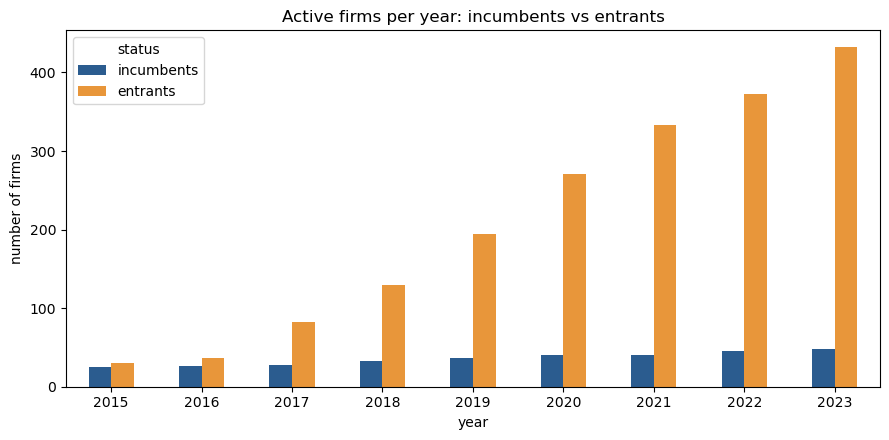

In [41]:
def incumbents_vs_entrants(links_all):
    "Number of active incumbents and entrants per year, from SPLIT_YEAR on."
    early = links_all[links_all["year"] < SPLIT_YEAR].groupby("firm")["family"].nunique()
    incumbents = early[early >= MIN_FAMILIES].index
    links = links_all[links_all["year"].between(SPLIT_YEAR, YEAR_MAX)]
    links = links.assign(status=np.where(links["firm"].isin(incumbents), "incumbents", "entrants"))
    return links.groupby(["year", "status"])["firm"].nunique().unstack(fill_value=0)[["incumbents", "entrants"]]


def plot_incumbents_vs_entrants(table):
    ax = table.plot.bar(figsize=(9, 4.5), rot=0, color=["#2b5c8f", "#e8963a"],
                        title="Active firms per year: incumbents vs entrants")
    ax.set(xlabel="year", ylabel="number of firms")
    plt.tight_layout()
    plt.show()


ie_table = incumbents_vs_entrants(links_all)
display(ie_table)
plot_incumbents_vs_entrants(ie_table)

**Results.** Incumbents stay a small, stable group (25 to 48 active a year). Active entrants grow from 30 in 2015 to about 430 in 2023: almost all the growth in the number of firms comes from newcomers.

**Limit.** "Entrant" means new to quantum patenting, not a new company: Baidu or Tencent are entrants here.

### Who are the entrants?
Patent data do not say whether a firm is a university spin-off. The 10 largest entrants (first family in or after `SPLIT_YEAR`) are therefore classified by hand from company websites and Crunchbase, into three groups:
- **University spin-off**: founded to commercialise university research
- **Independent start-up**: new firm not born from a university
- **Established company diversifying**: an existing company entering quantum computing

In [42]:
def firm_region(df):
    "Region of each firm: its most frequent applicant country, else office of first filing."
    country = df["applicant_ctry"].fillna(df["first_office"])
    return (df.assign(country=country).dropna(subset=["harmonized_name_final", "country"])
              .groupby("harmonized_name_final")["country"].agg(lambda s: s.mode().iat[0]).map(to_region))


def top_entrants(links, n=10):
    "Largest entrants with first year and region."
    all_firms = top_firms(links, n=links["firm"].nunique())
    entrants = all_firms[all_firms["status"] == "entrant"]
    table = entrants.head(n).drop(columns="status")
    table["region"] = table.index.map(firm_region(df))
    coverage = table["families"].sum() / entrants["families"].sum() * 100
    print(f"These {n} firms hold {coverage:.0f}% of the families of all {len(entrants):,} entrants (sum over firms).")
    return table


top_entrants(firms)

These 10 firms hold 36% of the families of all 1,161 entrants (sum over firms).


,families,first year,share (%),region
firm,,,,
ORIGIN QUANTUM COMPUTING TECH HEFEI,972,2017,10.8,China
BEIJING BAIDU NETCOM SCIENCE TECH,354,2019,4.0,China
IONQ,173,2017,1.9,US
RUBAN QUANTUM TECH,153,2018,1.7,China
QUANTINUUM,148,2015,1.7,US
RED HAT,124,2018,1.4,US
SUZHOU INSPUR INTELLIGENT TECH,98,2018,1.1,China
BANK AMERICA,91,2017,1.0,US
IQM FINLAND,84,2015,0.9,Europe


| Firm | Origin | Note |
|---|---|---|
| Origin Quantum | University spin-off | Founded 2017 by USTC / CAS researchers (Hefei) |
| Baidu | Established company diversifying | Chinese internet and AI group |
| IonQ | University spin-off | Founded 2015 on trapped-ion research licensed from Univ. of Maryland and Duke |
| Ruban Quantum | Independent start-up | Founded 2017; quantum information technologies, including quantum communication and cryptography |
| Quantinuum | Established company diversifying | Formed 2021 from Honeywell Quantum Solutions and Cambridge Quantum |
| Red Hat | Established company diversifying | Software firm, part of IBM since 2019 |
| Bank of America | Established company diversifying | Bank; patents on quantum applications (user, not hardware) |
| Inspur | Established company diversifying | Chinese server and IT manufacturer |
| IQM Finland | University spin-off | Founded 2018 as a spin-off of Aalto University and VTT |
| Tencent | Established company diversifying | Chinese internet group |

**Reading:** by number, most large entrants are established companies diversifying into quantum (6 of 10). By families, university spin-offs weigh more (about 54%, against 39% for established companies and 7% for the one independent start-up), but this is driven by Origin Quantum alone. Entry follows two tracks: research spin-offs and large incumbents from other industries. Independent start-ups are rare.

## 8. Key findings

### How concentrated is the field, and is it consolidating?
- **Moderately concentrated.** The 4 largest firms hold 24% of company families, the 8 largest 32%; 1/HHI ≈ 44, as if 43 equal-sized firms competed. Gini ≈ 0.79: a few large filers and a long tail of firms with one or two families.
- **Not consolidating, but widening.** CR4 falls from 36% (up to 2014) to 26% (2019–2023) and 1/HHI rises from about 20 to 38. Newcomers take share faster than the leaders grow.

### Who are the incumbents, and who are the new entrants?
- **Incumbents** (active before 2015) are a small, stable group of 25–48 active firms a year: large US IT firms (IBM, Microsoft, Google, Intel), Japanese electronics and telecom groups (Fujitsu, NTT, NEC, Toshiba, Hitachi), defence (Northrop Grumman) and two early quantum start-ups (D-Wave, Rigetti).
- **Entrants** drive the growth: from 30 active in 2015 to about 430 in 2023. The largest follow two tracks: **university spin-offs** (Origin Quantum, IonQ, IQM) and **established companies diversifying into quantum** (Baidu, Tencent, Inspur, Red Hat, Bank of America, Quantinuum). Independent start-ups are rare.
- 8 of the 20 largest filers are entrants, and the largest of all, Origin Quantum, only started filing in 2017.

### Other findings
- **A young, fast-growing field.** Families rose from about 75 a year in 2010 to about 2,900 in 2023; more than three quarters were filed in 2019–2023.
- **Companies lead.** 63% of families are filed by companies alone, 19% by universities alone; joint company–university filing is rare (2.4%).
- **China has overtaken the US.** China files more families than the US since 2021 (about 1,380 vs 610 in 2023), while US filing has been flat at about 600 a year. Chinese patenting moved from universities (94% of families in 2010) to companies (68% in 2023); in the US companies have held more than 80% throughout.
- **Volume is not reach.** In 2017–2021 IBM filed more families than Origin (495 vs 379), and 58% of them in two or more offices against 14% for Origin. Origin overtakes IBM by count only in 2022–2023, with mostly domestic filings: a high count reflects a filing strategy, not necessarily a larger portfolio.

### Data limitations

- **Counts, not value.** Every family counts once, whether it is filed in one office or worldwide, and whatever its citations. Rankings by count favour domestic filing strategies (see IBM vs Origin).
- **Country.** The applicant country is missing for 42% of rows, mostly Chinese filings; there the office of first filing is used instead.
- **Harmonization.** Names are harmonized with a general pipeline (cleaning, brand key, fuzzy matching; precision 0.96 and recall 0.94 on the course gold standard), plus a few manual corrections for the largest firms (IBM, Origin Quantum, NTT, D-Wave). Remaining errors are in the long tail and do not move the concentration measures. Acquisitions are not merged (Red Hat counted apart from IBM, Quantinuum apart from Honeywell), and applicant type comes from an imputed sector. These can move single firms, not the overall trends.
- **Boundary of the field.** Quantum computing shares technologies and applicants with quantum communication and cryptography, so the dataset also includes some patents at this boundary (e.g. Ruban Quantum). 
- **Recent years.** Applications are published about 18 months after filing, so 2023 may be slightly undercounted; it is still higher than 2022, so the trend is not affected Filings in other offices arrive about 30 months later, which is why the IBM–Origin comparison stops at 2021.
- **Manual classification.** Only the 10 largest entrants (36% of entrant families) are classified as spin-off, start-up or established company, from public sources.

## Pest

## Political

**What our data show (filings up to 2023).** Quantum is a strategic priority for governments, and the timing fits our data. China named quantum in its 13th (2016) and 14th (2021) Five-Year Plans; Chinese filings rose from about 60 families in 2016 to about 1,380 in 2023, overtaking the US in 2021, and moved from universities to companies. The US launched its [National Quantum Initiative](https://www.quantum.gov/) in 2018: US filings tripled between 2016 and 2019, then levelled off at about 600 a year. Europe's [Quantum Flagship](https://qt.eu/) (2018) came with steady growth, from about 40 families in 2015 to about 465 in 2023. These are timing coincidences, not proof of cause.

**What happened after our data, and what new PATSTAT data should show.**
- **Rivalry:** in September 2024 the US introduced [export controls on quantum computers and components](https://www.quantum.gov/department-of-commerce-releases-export-controls-on-quantum-technologies/).
- **United States:** a [bill to renew the National Quantum Initiative to 2034](https://www.commerce.senate.gov/2026/1/cantwell-young-colleagues-introduce-bipartisan-national-quantum-initiative-reauthorization-act) was introduced in January 2026.
- **Europe:** the EU adopted a [Quantum Strategy](https://digital-strategy.ec.europa.eu/en/library/quantum-europe-strategy) in 2025 and is preparing a Quantum Act.
- **China:** the [15th Five-Year Plan (2026–2030)](https://www.china-briefing.com/news/chinas-quantum-technology-15th-fyp-commercialization/) puts quantum first among "future industries" and moves funding from university research to commercialisation.

*Expected in future data:* a further rise of Chinese company filings, and more European filings as EU programmes scale up.


## Economic

**What our data show (filings up to 2023).** The field is opening up, not closing. Active entrants grew from 31 firms in 2015 to about 430 in 2023, and the share of the 4 largest firms fell from 36% to 26%. The largest entrants are university spin-offs (Origin Quantum, IonQ, IQM) and large companies from other sectors moving into quantum (Baidu, Tencent, Bank of America): building quantum computers is expensive, so either deep research or deep pockets is needed.

**What happened after our data, and what new PATSTAT data should show.**
- **Investment boom:** according to [McKinsey's Quantum Technology Monitor 2026](https://www.mckinsey.com/featured-insights/charts/quantum-investment-surge), investment in quantum start-ups reached 12.6 billion in 2025, 6.3 times 2024, almost all of it private.
- **First consolidation:** [IonQ bought Oxford Ionics](https://innovation.ox.ac.uk/news/quantum-leap-story-behind-university-oxfords-highest-value-quantum-computing-spinout-acquisition) (a University of Oxford spin-off) for about $1.1 billion in 2025, and in 2026 several quantum firms went public (Quantinuum, Xanadu, Pasqal, Infleqtion, Horizon Quantum).

*Expected in future data:* many more filings from well-funded start-ups after 2024, and possibly the first signs of consolidation. Once acquisitions are reflected in applicant names, concentration could rise again after falling until 2023.

## Social

**What our data show (filings up to 2023).** Quantum computing is still close to research. Universities file 19% of all families, and three of the ten largest entrants are university spin-offs. Joint company–university patents are rare (2.4%): knowledge moves mostly through people who leave the lab to found or join companies, not through co-owned patents.

**What happened after our data, and what new PATSTAT data should show.**
- **Talent shortage:** the [MIT Quantum Index Report 2025](https://qir.mit.edu/workforce) finds that US job postings requiring quantum skills have almost tripled since 2018, and the [World Economic Forum](https://www.weforum.org/stories/2025/11/upskilling-quantum-talent) describes a growing talent gap across roles, from engineers to business staff.
- **Public awareness:** the UN declared 2025 the [International Year of Quantum Science and Technology](https://physicsworld.com/a/its-official-united-nations-declares-2025-the-international-year-of-quantum-science-and-technology/).
- **Security:** fear that future quantum computers could break today's encryption led NIST to publish the first [post-quantum cryptography standards](https://www.nist.gov/node/1919116) in August 2024 and a migration roadmap in 2026.

*Expected in future data:* more spin-offs from universities as investors look for scarce talent, and more patents at the boundary between quantum computing and data security.

## Technological

**What our data show (filings up to 2023).** Filing accelerates after 2017–2019, the years when quantum computers became accessible through the cloud (IBM, 2016) and Google claimed a first "quantum advantage" with its Sycamore chip (2019). No single design has won yet: the top filers use different technologies (superconducting qubits for IBM, Google and Origin; trapped ions for IonQ and Quantinuum; annealing for D-Wave), which keeps the door open to new entrants. Software firms and users (Red Hat, Baidu, Bank of America) appear among the entrants, a sign that the cloud lowered the entry barrier.

**What happened after our data, and what new PATSTAT data should show.**
- **Error correction:** in December 2024 Google's [Willow chip](https://www.scientificamerican.com/article/google-makes-a-major-quantum-computing-breakthrough/) showed for the first time that errors go down as more qubits are added, the main obstacle on the road to useful quantum computers ([plain-language explanation](https://www.techtarget.com/searchcio/definition/Google-Willow)).
- **The race moves to engineering:** companies now compete on manufacturing reliable qubits at scale, for example on standard chips, as in the Oxford Ionics technology bought by IonQ.

*Expected in future data:* a strong rise of patents on error correction and on scalable hardware, filed from 2025 and visible in PATSTAT from about 2026–2027.